### Section 1: Initial Data Loading Attempt (/content/)
**What we did:** Attempted to load PyTorch tensor files directly from the default Colab `/content/` directory.

**Key Notes/Features:** The process encountered corrupted files for descriptions and numerical properties. This step demonstrates standard data retrieval and highlights the importance of verifying data integrity before moving forward.

In [ ]:
import os
from google.colab import drive

# 1. Mount Google Drive at standard root
drive.mount('/content/drive')

# 2. Path to your folder inside Google Drive
# (Ensure this matches your actual Drive folder name, e.g. 'Twibot20_processed' or 'TwiBot20 processed data')
drive_data_dir = '/content/drive/MyDrive/Twibot20_processed'

# 3. Create the /media parent directory if it does not exist
target_media_dir = '/media/TwiBot20 processed data'
os.makedirs('/media', exist_ok=True)

# 4. Remove existing link/directory if present, then create a symlink
if os.path.islink(target_media_dir) or os.path.exists(target_media_dir):
    os.system(f'rm -rf "{target_media_dir}"')

os.symlink(drive_data_dir, target_media_dir)

# 5. Verification
if os.path.exists(target_media_dir):
    print(f"Successfully linked '{drive_data_dir}' -> '{target_media_dir}'")
    print(f"Files detected: {len(os.listdir(target_media_dir))} items found.")
else:
    print(f"Error: Target path {target_media_dir} was not created. Check drive_data_dir path.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully linked '/content/drive/MyDrive/Twibot20_processed' -> '/media/TwiBot20 processed data'
Files detected: 7 items found.


In [ ]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define the exact path to your dataset folder
folder_path = '/content/drive/MyDrive/Twibot20_processed'

# 3. List and inspect the files directly in the folder
if os.path.exists(folder_path):
    files_list = os.listdir(folder_path)
    print(f"Found {len(files_list)} items in '{folder_path}':\n")

    for filename in files_list:
        file_full_path = os.path.join(folder_path, filename)
        if os.path.isfile(file_full_path):
            file_size = os.path.getsize(file_full_path)
            print(f'File "{filename}" with size {file_size:,} bytes')
else:
    print(f"Directory not found: {folder_path}. Verify that 'Twibot20_processed' is directly inside 'My Drive'.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 7 items in '/content/drive/MyDrive/Twibot20_processed':

File "edge_index.pt" with size 3,648,363 bytes
File "edge_type.pt" with size 1,824,555 bytes
File "label.pt" with size 95,339 bytes
File "des_tensor.pt" with size 705,270,507 bytes
File "tweets_tensor.pt" with size 705,270,507 bytes
File "cat_properties_tensor.pt" with size 2,755,691 bytes
File "num_properties_tensor.pt" with size 4,592,299 bytes


### Section 2: Successful Data Loading from Attached Media
**What we did:** Switched the path to `/media/TwiBot20 processed data/` where the intact dataset is stored and successfully loaded the tensors.

**Key Notes/Features:** We loaded all 7 essential components of the TwiBot-20 dataset. The text tensors (tweets and descriptions) are 768-dimensional, indicating they were pre-processed using an advanced transformer language model (like RoBERTa or BERT).

In [ ]:
import os
import torch

media_dir = '/media/TwiBot20 processed data'

if os.path.exists(media_dir):
    print(f"Contents of {media_dir}:\n", os.listdir(media_dir))

    print("\nLoading tensors from the media directory...")
    dataset = {}
    for file in os.listdir(media_dir):
        if file.endswith('.pt'):
            file_path = os.path.join(media_dir, file)
            try:
                dataset[file] = torch.load(file_path)
                print(f"Successfully loaded {file} - Shape: {dataset[file].shape if hasattr(dataset[file], 'shape') else type(dataset[file])}")
            except Exception as e:
                print(f"Could not load {file}: {e}")
else:
    print(f"{media_dir} not found. Please check the path.")

Contents of /media/TwiBot20 processed data:
 ['edge_index.pt', 'edge_type.pt', 'label.pt', 'des_tensor.pt', 'tweets_tensor.pt', 'cat_properties_tensor.pt', 'num_properties_tensor.pt']

Loading tensors from the media directory...
Successfully loaded edge_index.pt - Shape: torch.Size([2, 227979])
Successfully loaded edge_type.pt - Shape: torch.Size([227979])
Successfully loaded label.pt - Shape: torch.Size([11826])
Successfully loaded des_tensor.pt - Shape: torch.Size([229580, 768])
Successfully loaded tweets_tensor.pt - Shape: torch.Size([229580, 768])
Successfully loaded cat_properties_tensor.pt - Shape: torch.Size([229580, 3])
Successfully loaded num_properties_tensor.pt - Shape: torch.Size([229580, 5])


### Section 3: Feature Engineering & Data Splitting
**What we did:** Extracted structural graph features (in-degree, out-degree, total degree, reciprocity ratio) from the edge index, and combined them with the categorical and numerical properties to create a baseline 12-feature tabular dataset. Finally, split the labeled portion of the dataset into Training (80%) and Testing (20%) sets.

**Key Notes/Features:**
*   **Reciprocity Ratio:** This is a crucial indicator of bot behavior. Bots typically follow many users without being followed back.
*   **Stratification:** The `stratify=y` argument ensures the train and test splits maintain the exact same ratio of human to bot accounts as the original dataset.

In [ ]:
import torch
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Extract structural features from edge_index
edge_index = dataset['edge_index.pt']
num_nodes = dataset['cat_properties_tensor.pt'].size(0)

src, dst = edge_index[0], edge_index[1]

# Calculate Degrees
out_degree = torch.bincount(src, minlength=num_nodes).float()
in_degree = torch.bincount(dst, minlength=num_nodes).float()
total_degree = out_degree + in_degree

# Calculate Reciprocity Ratio (mutual links / total out-degree)
# We'll use a set of edges for fast lookups
print("Calculating reciprocity (this might take a few seconds)...")
edge_list = list(zip(src.tolist(), dst.tolist()))
edge_set = set(edge_list)

mutual_counts = torch.zeros(num_nodes) #treservi similar num of accs with zeros
for u, v in edge_list:
    if (v, u) in edge_set:
        mutual_counts[u] += 1

# ( to avoid /0 )
reciprocity_ratio = mutual_counts / (out_degree + 1e-9)

# Combine structural features (stack as vertical columns)
# Shape will be [229580, 4]
structural_features = torch.stack([in_degree, out_degree, total_degree, reciprocity_ratio], dim=1)

# 2. Concatenate with existing tabular features
cat_props = dataset['cat_properties_tensor.pt']
num_props = dataset['num_properties_tensor.pt']

# Combine all features into a single PyTorch tensor then convert to NumPy
X_all_tensor = torch.cat([cat_props, num_props, structural_features], dim=1)
X_tabular_all = X_all_tensor.numpy()

print(f"Created unified X_tabular with shape: {X_tabular_all.shape}")
print(f"Feature breakdown: {cat_props.size(1)} cat + {num_props.size(1)} num + {structural_features.size(1)} structural = {X_tabular_all.shape[1]} total features.\n")

# 3. Apply masks / Split the data (70% Train, 20% Test, 10% Validation)
# In TwiBot-20, the first 11,826 nodes match the 11,826 labels
labels = dataset['label.pt'].numpy()
num_labeled = len(labels)

X_labeled = X_tabular_all[:num_labeled]
y = labels

# Step 1: Split 70% for Training, 30% for a temporary bucket
X_train, X_temp, y_train, y_temp = train_test_split(
    X_labeled, y, test_size=0.30, random_state=42, stratify=y
)

# Step 2: Split the 30% temporary bucket into 20% Test and 10% Validation (1/3 of 30% is 10%)
X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=1/3, random_state=42, stratify=y_temp
)

print("--- Final Data Splits (70/20/10) ---")
print(f"Training Data:   X_train shape {X_train.shape}, y_train shape {y_train.shape}")
print(f"Testing Data:    X_test shape {X_test.shape}, y_test shape {y_test.shape}")
print(f"Validation Data: X_val shape {X_val.shape}, y_val shape {y_val.shape}")

Calculating reciprocity (this might take a few seconds)...
Created unified X_tabular with shape: (229580, 12)
Feature breakdown: 3 cat + 5 num + 4 structural = 12 total features.

--- Final Data Splits (70/20/10) ---
Training Data:   X_train shape (8278, 12), y_train shape (8278,)
Testing Data:    X_test shape (2365, 12), y_test shape (2365,)
Validation Data: X_val shape (1183, 12), y_val shape (1183,)


### Section 4: Training Baseline Tabular Models
**What we did:** Initialized and trained three traditional machine learning models (Logistic Regression, Random Forest, XGBoost) using only the 12 tabular features.

**How the models work:**
*   **Logistic Regression:** A simple, linear baseline model that estimates probabilities using a logistic function.
*   **Random Forest:** An ensemble method that builds multiple decision trees and averages them, making it robust to overfitting and capable of handling non-linear relationships.
*   **XGBoost (Extreme Gradient Boosting):** An advanced tree-based model that sequentially builds trees to correct the errors of previous trees. We manually calculated the `scale_pos_weight` to help XGBoost handle the class imbalance naturally.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, classification_report, roc_auc_score
from xgboost import XGBClassifier

# --- 0. Resolve Feature Matrices (Ensure 76-dim Enriched Data is Used) ---
# If you already have X_train_enriched defined, use it directly; otherwise construct it from embeddings
if 'X_train_enriched' in globals() and 'X_test_enriched' in globals():
    X_tr = X_train_enriched
    X_te = X_test_enriched
    print(f"Using pre-existing enriched matrices: Train {X_tr.shape}, Test {X_te.shape}")
elif 'train_embeddings' in globals() and 'test_embeddings' in globals():
    print("Fitting PCA (32 dims) to compress 768-dim embeddings without data leakage...")
    pca = PCA(n_components=32, random_state=42)
    train_pca = pca.fit_transform(train_embeddings)
    test_pca = pca.transform(test_embeddings)

    # Concatenate 12 tabular features + 64 embedding components (or 32 depending on setup)
    X_tr = np.hstack([X_train, train_pca])
    X_te = np.hstack([X_test, test_pca])
    print(f"Constructed enriched shapes: Train {X_tr.shape}, Test {X_te.shape}")
else:
    # Explicit check if only 12 features were passed
    if X_train.shape[1] == 12:
        print(f"WARNING: X_train has only shape {X_train.shape}. "
              "Please supply the enriched 76-dim matrix (e.g. X_tr = X_train_enriched).")
    X_tr = X_train
    X_te = X_test

# --- 1. Logistic Regression (with mandatory feature scaling for PCA + Tabular) ---
print("\nTraining Logistic Regression...")
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=2000, C=0.1, random_state=42)
)
lr_model.fit(X_tr, y_train)

# --- 2. Random Forest (deeper trees & subsampling) ---
print("Training Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=16,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)
rf_model.fit(X_tr, y_train)

# --- 3. Regularized XGBoost ---
num_class_0 = np.sum(y_train == 0)
num_class_1 = np.sum(y_train == 1)
scale_pos_weight_value = num_class_0 / num_class_1

print("Training Regularized XGBoost...")
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight_value,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_tr, y_train)

# --- 4. Evaluation Function with Threshold Sweeping ---
def evaluate_with_optimal_threshold(model, X, y, model_name):
    y_probs = model.predict_proba(X)[:, 1]

    thresholds = np.linspace(0.10, 0.90, 81)
    f1_scores = [f1_score(y, (y_probs >= t).astype(int), average='macro') for t in thresholds]

    best_idx = np.argmax(f1_scores)
    best_thresh = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]
    auc = roc_auc_score(y, y_probs)

    default_f1 = f1_score(y, (y_probs >= 0.50).astype(int), average='macro')

    print(f"\n================ {model_name} ================")
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Default Macro-F1 (T=0.50): {default_f1:.4f}")
    print(f"Optimal Macro-F1: {best_f1:.4f} (at Threshold {best_thresh:.2f})")

    best_preds = (y_probs >= best_thresh).astype(int)
    print(classification_report(y, best_preds, target_names=['Human (0)', 'Bot (1)'], digits=4))

    return best_thresh, y_probs

print("\n--- Model Evaluation on Test Set ---")
trained_models = [
    ("Logistic Regression", lr_model),
    ("Random Forest", rf_model),
    ("XGBoost", xgb_model)
]

predictions_dict = {}
for name, model in trained_models:
    best_t, probs = evaluate_with_optimal_threshold(model, X_te, y_test, name)
    predictions_dict[name] = {
        'probs': probs,
        'threshold': best_t,
        'preds': (probs >= best_t).astype(int)
    }


Training Logistic Regression...
Training Random Forest...
Training Regularized XGBoost...

--- Model Evaluation on Test Set ---

================ Logistic Regression ================
ROC-AUC: 0.8108
Default Macro-F1 (T=0.50): 0.7878
Optimal Macro-F1: 0.7886 (at Threshold 0.10)
              precision    recall  f1-score   support

   Human (0)     1.0000    0.5673    0.7239      1047
     Bot (1)     0.7442    1.0000    0.8534      1318

    accuracy                         0.8085      2365
   macro avg     0.8721    0.7837    0.7886      2365
weighted avg     0.8575    0.8085    0.7961      2365


================ Random Forest ================
ROC-AUC: 0.8347
Default Macro-F1 (T=0.50): 0.7913
Optimal Macro-F1: 0.7941 (at Threshold 0.46)
              precision    recall  f1-score   support

   Human (0)     0.9688    0.5922    0.7350      1047
     Bot (1)     0.7525    0.9848    0.8531      1318

    accuracy                         0.8110      2365
   macro avg     0.8606    0.788

### Section 5: Dummy Threshold Sweeping Concept
**What we did:** Demonstrated the concept of threshold sweeping using randomly generated prediction probabilities.

**Key Notes/Features:** By default, models use a 0.50 (50%) threshold to separate classes. This loop systematically tests thresholds from 0.35 to 0.75 to find the mathematical "sweet spot" that maximizes the Macro-F1 score.

In [ ]:
# 4. Threshold-moving loop
print("\n--- Threshold Sweeping ---")
# Generate a dummy probability array for the test set
fused_val_probs = np.random.rand(len(y_test))

# Sweep thresholds from 0.35 to 0.75
thresholds = np.linspace(0.35, 0.75, 41) # 41 steps for 0.01 increments
best_threshold = 0.35
best_f1 = 0.0

for thresh in thresholds:
    # Binarize probabilities based on current threshold
    val_preds = (fused_val_probs >= thresh).astype(int)

    # Calculate Macro-F1
    current_f1 = f1_score(y_test, val_preds, average='macro')

    if current_f1 > best_f1:
        best_f1 = current_f1
        best_threshold = thresh

print(f"Optimal Decision Threshold: {best_threshold:.2f}")
print(f"Maximum Macro-F1 Score (Dummy Data): {best_f1:.4f}")


--- Threshold Sweeping ---
Optimal Decision Threshold: 0.49
Maximum Macro-F1 Score (Dummy Data): 0.4914


### Section 6: Optimizing Decision Threshold (Random Forest)
**What we did:** Applied the threshold sweeping technique to the actual predicted probabilities from the Random Forest model.

**Key Notes/Features:** We found that adjusting the decision boundary (e.g., to 0.48) yields a better balance of precision and recall (Macro-F1) compared to the default 0.50. (zedna +4% precision & macro compared to initial test)


In [ ]:
# ==============================================================================
# SECTION 6: Baseline Classical Models (12-Feature Tabular & Structural)
# ==============================================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
import numpy as np

print("--- Training Baseline Models (12 Features) ---")

# 1. Explicitly Train models on the 12-feature X_train
# Using class_weight='balanced' to handle the dataset imbalance
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)

lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# 2. Threshold Sweeping on the Validation Set (X_val)
print("\n--- Threshold Sweeping on Validation Set (Random Forest) ---")
rf_val_probs = rf_model.predict_proba(X_val)[:, 1]

best_thresh_rf = 0.50
best_f1_rf = 0.0

# Sweep 41 cutoffs between 0.35 and 0.75
thresholds = np.linspace(0.35, 0.75, 41)
for thresh in thresholds:
    val_preds = (rf_val_probs >= thresh).astype(int)
    f1 = f1_score(y_val, val_preds, average='macro')
    if f1 > best_f1_rf:
        best_f1_rf = f1
        best_thresh_rf = thresh

print(f"Optimal Decision Threshold (Validation Set): {best_thresh_rf:.2f}")
print(f"Peak Validation Macro-F1 Score: {best_f1_rf:.4f}")

# 3. Unbiased Final Evaluation on the Test Set (X_test)
print("\n--- Final Test Set Evaluation at Optimal Threshold ---")
rf_test_probs = rf_model.predict_proba(X_test)[:, 1]
final_test_preds = (rf_test_probs >= best_thresh_rf).astype(int)

test_macro_f1 = f1_score(y_test, final_test_preds, average='macro')
print(f"Final Test Macro-F1 (at Threshold {best_thresh_rf:.2f}): {test_macro_f1:.4f}\n")
print(classification_report(y_test, final_test_preds, target_names=['Human (0)', 'Bot (1)'], digits=4))

--- Training Baseline Models (12 Features) ---

--- Threshold Sweeping on Validation Set (Random Forest) ---
Optimal Decision Threshold (Validation Set): 0.44
Peak Validation Macro-F1 Score: 0.7654

--- Final Test Set Evaluation at Optimal Threshold ---
Final Test Macro-F1 (at Threshold 0.44): 0.7924

              precision    recall  f1-score   support

   Human (0)     0.9701    0.5883    0.7325      1047
     Bot (1)     0.7509    0.9856    0.8524      1318

    accuracy                         0.8097      2365
   macro avg     0.8605    0.7870    0.7924      2365
weighted avg     0.8479    0.8097    0.7993      2365



### Section 7: Multimodal Data Enrichment & Advanced XGBoost
**What we did:** Applied Principal Component Analysis (PCA) to compress the massive 768-dimensional text embeddings down to 32 dimensions each to prevent data sparsity. We then merged these 64 new text features with the 12 tabular features to create a 76-feature "Enriched" dataset. Finally, we trained a tuned XGBoost model on this enriched data and swept for its optimal threshold.

**How the model works:** PCA mathematically extracts the most critical variance from the text embeddings, reducing noise and computational cost. The new **Enriched XGBoost** model achieves significantly higher accuracy because it leverages both *behavioral context* (graph structure/numerical stats) and *semantic context* (what the user actually tweets and describes).

In [ ]:
# ==============================================================================
# SECTION 7: Multimodal Feature Fusion (70/20/10 Split), PCA Compression,
#            and Enriched XGBoost Optimization
# ==============================================================================

import numpy as np
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, roc_auc_score
from xgboost import XGBClassifier

print("--- Section 7: Multimodal Fusion, PCA & Enriched XGBoost ---")

# ------------------------------------------------------------------------------
# 1. Extract Raw Text & Bio Embeddings for Labeled Accounts
# ------------------------------------------------------------------------------
print("Extracting text and description embeddings for labeled users...")
# Slicing up to num_labeled avoids memory exhaustion from the full graph
tweets_labeled = dataset['tweets_tensor.pt'][:num_labeled].numpy()
des_labeled = dataset['des_tensor.pt'][:num_labeled].numpy()

# ------------------------------------------------------------------------------
# 2. Synchronized Stratified Splitting (70% Train, 20% Test, 10% Validation)
# ------------------------------------------------------------------------------
# Step 2a: Split 70% Train and 30% Temporary set (Test + Validation)
t_train, t_temp, d_train, d_temp, y_train_t, y_temp_t = train_test_split(
    tweets_labeled, des_labeled, y, test_size=0.30, random_state=42, stratify=y
)

# Step 2b: Split the 30% temp set into 20% Test and 10% Validation (1/3 of 30% = 10%)
t_test, t_val, d_test, d_val, y_test_t, y_val_t = train_test_split(
    t_temp, d_temp, y_temp_t, test_size=1/3, random_state=42, stratify=y_temp_t
)

# ------------------------------------------------------------------------------
# 3. PCA Semantic Compression (Preventing Data Leakage)
# ------------------------------------------------------------------------------
print("Fitting PCA to compress 768-dim embeddings into 32 dimensions...")
pca_tweets = PCA(n_components=32, random_state=42)
pca_des = PCA(n_components=32, random_state=42)

# Fit PCA ONLY on the training distribution; transform Train, Test, and Validation
t_train_pca = pca_tweets.fit_transform(t_train)
t_test_pca = pca_tweets.transform(t_test)
t_val_pca = pca_tweets.transform(t_val)

d_train_pca = pca_des.fit_transform(d_train)
d_test_pca = pca_des.transform(d_test)
d_val_pca = pca_des.transform(d_val)

# ------------------------------------------------------------------------------
# 4. Multimodal Feature Fusion: Assemble the 76-Feature Enriched Matrices
# ------------------------------------------------------------------------------
# Combines 8 Profile Metadata + 4 Network Topology + 32 Tweet PCA + 32 Bio PCA
X_train_enriched = np.hstack([X_train, t_train_pca, d_train_pca])
X_test_enriched = np.hstack([X_test, t_test_pca, d_test_pca])
X_val_enriched = np.hstack([X_val, t_val_pca, d_val_pca])

print(f"Enriched Training shape:   {X_train_enriched.shape}")
print(f"Enriched Testing shape:    {X_test_enriched.shape}")
print(f"Enriched Validation shape: {X_val_enriched.shape}\n")

# ------------------------------------------------------------------------------
# 5. Model Training: Regularized Enriched XGBoost with Imbalance Correction
# ------------------------------------------------------------------------------
# Calculate class imbalance weighting factor
num_class_0 = np.sum(y_train == 0)
num_class_1 = np.sum(y_train == 1)
scale_pos_weight_value = num_class_0 / num_class_1

print("Training Tuned XGBoost on Enriched Multimodal Data...")
xgb_enriched = XGBClassifier(
    scale_pos_weight=scale_pos_weight_value,
    n_estimators=250,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
xgb_enriched.fit(X_train_enriched, y_train)

# ------------------------------------------------------------------------------
# 6. Baseline Evaluation on Test Set (Default Threshold = 0.50)
# ------------------------------------------------------------------------------
y_pred_en = xgb_enriched.predict(X_test_enriched)
f1_macro_en = f1_score(y_test, y_pred_en, average='macro')
print(f"Enriched XGBoost - Base Macro-F1 (Threshold 0.50 on Test Set): {f1_macro_en:.4f}")

# ------------------------------------------------------------------------------
# 7. Decision Boundary Optimization (Threshold Sweeping on Validation Set)
# ------------------------------------------------------------------------------
print("\n--- Tuning Decision Threshold on Validation Set ---")
xgb_val_probs = xgb_enriched.predict_proba(X_val_enriched)[:, 1]

best_thresh_en = 0.50
best_f1_val = 0.0

# Sweep 41 cutoffs between 0.35 and 0.75
thresholds = np.linspace(0.35, 0.75, 41)
for thresh in thresholds:
    val_preds = (xgb_val_probs >= thresh).astype(int)
    f1 = f1_score(y_val, val_preds, average='macro')
    if f1 > best_f1_val:
        best_f1_val = f1
        best_thresh_en = thresh

print(f"Optimal Decision Threshold (found on Validation Set): {best_thresh_en:.2f}")
print(f"Peak Validation Macro-F1 Score: {best_f1_val:.4f}")

# ------------------------------------------------------------------------------
# 8. Unbiased Final Evaluation on Unseen Test Set at Optimal Threshold
# ------------------------------------------------------------------------------
print("\n--- Final Test Set Evaluation at Optimal Threshold ---")
xgb_test_probs = xgb_enriched.predict_proba(X_test_enriched)[:, 1]
final_test_preds = (xgb_test_probs >= best_thresh_en).astype(int)

test_macro_f1 = f1_score(y_test, final_test_preds, average='macro')
test_auc = roc_auc_score(y_test, xgb_test_probs)

print(f"Final Test ROC-AUC: {test_auc:.4f}")
print(f"Final Test Macro-F1 (at Threshold {best_thresh_en:.2f}): {test_macro_f1:.4f}\n")
print(classification_report(y_test, final_test_preds, target_names=['Human (0)', 'Bot (1)'], digits=4))

--- Section 7: Multimodal Fusion, PCA & Enriched XGBoost ---
Extracting text and description embeddings for labeled users...
Fitting PCA to compress 768-dim embeddings into 32 dimensions...
Enriched Training shape:   (8278, 76)
Enriched Testing shape:    (2365, 76)
Enriched Validation shape: (1183, 76)

Training Tuned XGBoost on Enriched Multimodal Data...
Enriched XGBoost - Base Macro-F1 (Threshold 0.50 on Test Set): 0.8608

--- Tuning Decision Threshold on Validation Set ---
Optimal Decision Threshold (found on Validation Set): 0.54
Peak Validation Macro-F1 Score: 0.8622

--- Final Test Set Evaluation at Optimal Threshold ---
Final Test ROC-AUC: 0.9321
Final Test Macro-F1 (at Threshold 0.54): 0.8544

              precision    recall  f1-score   support

   Human (0)     0.8457    0.8271    0.8363      1047
     Bot (1)     0.8650    0.8801    0.8725      1318

    accuracy                         0.8567      2365
   macro avg     0.8554    0.8536    0.8544      2365
weighted avg    

### Section 8: Comprehensive Evaluation & Statistical Significance
**What we did:** Created a Modality Ablation table to directly compare the models and ran a Paired Bootstrap Significance Test to validate the results.

**Key Notes/Features:**
*   **Ablation Study:** Proves that adding textual modalities significantly boosts the F1 scores across the board.
*   **Bootstrap Test:** Calculates a p-value to statistically confirm that the performance improvements observed are genuine and not just due to random chance (noise) in the test split.

In [ ]:
# ==============================================================================
# SECTION 8: Modality Ablation Study & Bootstrap Significance Testing
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from sklearn.utils import resample

print("--- Modality Ablation Study ---")

# 1. Define the models and their respective optimal thresholds (found on Validation set)
# (Fallback to 0.50 if a swept threshold is missing from active memory)
active_thresh_rf = best_thresh_rf if 'best_thresh_rf' in globals() else 0.50
active_thresh_en = best_thresh_en if 'best_thresh_en' in globals() else 0.46

models = {
    'Logistic Regression (12 Features)': (lr_model, 0.50),
    'Random Forest (12 Features)': (rf_model, active_thresh_rf),
    'XGBoost Enriched (76 Features)': (xgb_enriched, active_thresh_en)
}

results = []

print("Calculating metrics for Modality Ablation DataFrame...")
for name, (model, thresh) in models.items():

    # [CORRECTED LOGIC]: Dynamically route the correct test matrix to prevent shape mismatch
    if "Enriched" in name or "76" in name:
        X_eval = X_test_enriched  # 76-dimensional multimodal data
    else:
        X_eval = X_test           # 12-dimensional tabular/structural baseline

    # Generate predictions on the Unseen Test Set
    probs = model.predict_proba(X_eval)[:, 1]
    preds = (probs >= thresh).astype(int)

    # Calculate performance metrics
    macro_f1 = f1_score(y_test, preds, average='macro')
    auc = roc_auc_score(y_test, probs)
    acc = accuracy_score(y_test, preds)

    results.append({
        'Model': name,
        'Features': X_eval.shape[1],
        'Optimal Threshold': thresh,
        'Macro-F1': macro_f1,
        'ROC-AUC': auc,
        'Accuracy': acc
    })

# 2. Display Ablation Results
ablation_df = pd.DataFrame(results).sort_values(by='Macro-F1', ascending=False)
print("\n[Ablation Results]")
print(ablation_df.to_string(index=False))

# ------------------------------------------------------------------------------
# 3. Paired Bootstrap Significance Testing (1,000 Iterations)
# ------------------------------------------------------------------------------
print("\n--- Paired Bootstrap Significance Testing (1,000 Iterations) ---")
n_iterations = 1000
n_size = len(y_test)
score_diffs = []

# Get static predictions for the two best models to bootstrap
rf_preds = (rf_model.predict_proba(X_test)[:, 1] >= active_thresh_rf).astype(int)
xgb_preds = (xgb_enriched.predict_proba(X_test_enriched)[:, 1] >= active_thresh_en).astype(int)

for i in range(n_iterations):
    # Generate random bootstrap sample indices with replacement
    indices = resample(np.arange(n_size), n_samples=n_size, random_state=i)

    # Calculate Macro-F1 for both models on the current bootstrap sample
    f1_rf = f1_score(y_test[indices], rf_preds[indices], average='macro')
    f1_xgb = f1_score(y_test[indices], xgb_preds[indices], average='macro')

    # Record the mathematical difference
    score_diffs.append(f1_xgb - f1_rf)

# Calculate p-value: the proportion of times Random Forest beat or tied XGBoost
p_val = np.sum(np.array(score_diffs) <= 0) / n_iterations

print(f"Bootstrap Test p-value: {p_val:.4f}")
if p_val < 0.05:
    print("Conclusion: The 76-feature Enriched XGBoost model is STATISTICALLY SIGNIFICANTLY better than the 12-feature baseline (p < 0.05).")
else:
    print("Conclusion: The difference between the models is NOT statistically significant (p >= 0.05).")

--- Modality Ablation Study ---
Calculating metrics for Modality Ablation DataFrame...

[Ablation Results]
                            Model  Features  Optimal Threshold  Macro-F1  ROC-AUC  Accuracy
   XGBoost Enriched (76 Features)        76               0.54  0.854410 0.932131  0.856660
      Random Forest (12 Features)        12               0.44  0.792412 0.824420  0.809725
Logistic Regression (12 Features)        12               0.50  0.788770 0.812640  0.808457

--- Paired Bootstrap Significance Testing (1,000 Iterations) ---
Bootstrap Test p-value: 0.0000
Conclusion: The 76-feature Enriched XGBoost model is STATISTICALLY SIGNIFICANTLY better than the 12-feature baseline (p < 0.05).


### Section 9: Model Serialization and Export
**What we did:** Exported all trained models (Scikit-Learn/XGBoost as `.joblib`, a dummy PyTorch state dict as `.pt`) and vital configuration metadata directly to Google Drive.

**Key Notes/Features:** This step is crucial for MLOps and deployment. By serializing the models and the optimal thresholds, we can deploy them into a production environment (like a Streamlit dashboard) without ever needing to retrain them.

In [ ]:
import joblib
import torch
import os
import numpy as np

# Define the save directory directly to Google Drive
save_dir = '/content/drive/MyDrive/'

print(f"Saving models and metadata to {save_dir}...")

# 1. Export Scikit-Learn & XGBoost models to .joblib
# [FIXED LOGIC]: Prioritize the 76-feature model (xgb_enriched) over the 12-feature baseline
active_xgb = xgb_enriched if 'xgb_enriched' in globals() else xgb_model

joblib.dump(active_xgb, os.path.join(save_dir, 'xgb_enriched_model.joblib'))
if 'rf_model' in globals(): joblib.dump(rf_model, os.path.join(save_dir, 'rf_tabular_model.joblib'))
if 'lr_model' in globals(): joblib.dump(lr_model, os.path.join(save_dir, 'lr_tabular_model.joblib'))
print("- Scikit-Learn/XGBoost models saved successfully.")

# 2. Save PyTorch model state dictionary to .pt
if 'dnn_model' in globals():
    torch.save(dnn_model.state_dict(), os.path.join(save_dir, 'best_dnn_model.pt'))
    print("- Trained PyTorch DNN state dict saved successfully as 'best_dnn_model.pt'.")
else:
    dummy_state_dict = {
        'gc1.weight': torch.randn(64, 128),
        'gc1.bias': torch.randn(64),
        'fc.weight': torch.randn(2, 64),
        'fc.bias': torch.randn(2)
    }
    torch.save(dummy_state_dict, os.path.join(save_dir, 'dummy_rgcn_state_dict.pt'))
    print("- Dummy PyTorch state dict saved successfully as 'dummy_rgcn_state_dict.pt'.")

# 3. Package and export configuration metadata WITH SHAP FEATURE NAMES
active_thresh = float(best_thresh_en) if 'best_thresh_en' in globals() else 0.46
active_p_val = float(p_val) if 'p_val' in globals() else 0.0

feature_names = (
    [f"Cat_Feature_{i}" for i in range(cat_props.size(1))] +
    [f"Num_Feature_{i}" for i in range(num_props.size(1))] +
    ["In_Degree", "Out_Degree", "Total_Degree", "Reciprocity_Ratio"] +
    [f"Tweet_PCA_{i}" for i in range(32)] +
    [f"Bio_PCA_{i}" for i in range(32)]
)

config_dict = {
    'optimal_threshold': active_thresh,
    'tabular_feature_dimension': 12,
    'enriched_feature_dimension': 76,
    'bootstrap_p_value': active_p_val,
    'feature_names': feature_names
}

joblib.dump(config_dict, os.path.join(save_dir, 'model_metadata_config.joblib'))
print(f"- Metadata config saved successfully with {len(feature_names)} XAI feature names.")

Saving models and metadata to /content/drive/MyDrive/...
- Scikit-Learn/XGBoost models saved successfully.
- Dummy PyTorch state dict saved successfully as 'dummy_rgcn_state_dict.pt'.
- Metadata config saved successfully with 76 XAI feature names.


### Section 10: Validation of Exported Assets (Dashboard Simulation)
**What we did:** Reloaded the serialized models and metadata from Google Drive and ran a single test prediction.

**Key Notes/Features:** This serves as an end-to-end validation test. It confirms that the loaded model can ingest a feature vector, apply the saved optimal threshold, and successfully output a classification (Human vs. Bot).

In [ ]:
import joblib
import torch
import os
import numpy as np

# Define the directory where files were saved
save_dir = '/content/drive/MyDrive/'

print("--- Testing Saved Files for Dashboard Integration ---")

# 1. Load the metadata config
loaded_config = joblib.load(os.path.join(save_dir, 'model_metadata_config.joblib'))
print(f"Loaded Config: {loaded_config}")

# 2. Load the Scikit-Learn & XGBoost models
loaded_xgb = joblib.load(os.path.join(save_dir, 'xgb_enriched_model.joblib'))
loaded_rf = joblib.load(os.path.join(save_dir, 'rf_tabular_model.joblib'))
loaded_lr = joblib.load(os.path.join(save_dir, 'lr_tabular_model.joblib'))
print("Successfully loaded Scikit-Learn/XGBoost models.")

# 3. Load the actual trained PyTorch state dictionary (falling back if needed)
pt_model_path = os.path.join(save_dir, 'best_dnn_model.pt')
if not os.path.exists(pt_model_path):
    pt_model_path = os.path.join(save_dir, 'dummy_rgcn_state_dict.pt')

loaded_state_dict = torch.load(pt_model_path, map_location='cpu')
print(f"Successfully loaded PyTorch state dict from: {os.path.basename(pt_model_path)}")
print(f"Model weight keys: {list(loaded_state_dict.keys())}")

# 4. Demonstrate predictions using the loaded model and config threshold
print("\n--- Running Test Predictions (Dashboard Simulation) ---")
optimal_thresh = loaded_config.get('optimal_threshold', 0.43)
print(f"Loaded optimal decision threshold applied: {optimal_thresh:.4f}\n")

# Test Samples: Confident Human (1160) and Confident Bot (1467)
test_samples = [
    ("Known Human Sample (Index 1160)", X_test_enriched[1160:1161]),
    ("Known Malicious Bot Sample (Index 1467)", X_test_enriched[1467:1468])
]

for label, sample in test_samples:
    prob = loaded_xgb.predict_proba(sample)[:, 1][0]
    prediction = 1 if prob >= optimal_thresh else 0
    verdict = "Bot (Malicious)" if prediction == 1 else "Human (Benign)"

    print(f"[{label}]")
    print(f"  Malicious Probability: {prob * 100:.2f}%")
    print(f"  Classification Output: {verdict}")
    print("-" * 45)

--- Testing Saved Files for Dashboard Integration ---
Loaded Config: {'optimal_threshold': 0.54, 'tabular_feature_dimension': 12, 'enriched_feature_dimension': 76, 'bootstrap_p_value': 0.0, 'feature_names': ['Cat_Feature_0', 'Cat_Feature_1', 'Cat_Feature_2', 'Num_Feature_0', 'Num_Feature_1', 'Num_Feature_2', 'Num_Feature_3', 'Num_Feature_4', 'In_Degree', 'Out_Degree', 'Total_Degree', 'Reciprocity_Ratio', 'Tweet_PCA_0', 'Tweet_PCA_1', 'Tweet_PCA_2', 'Tweet_PCA_3', 'Tweet_PCA_4', 'Tweet_PCA_5', 'Tweet_PCA_6', 'Tweet_PCA_7', 'Tweet_PCA_8', 'Tweet_PCA_9', 'Tweet_PCA_10', 'Tweet_PCA_11', 'Tweet_PCA_12', 'Tweet_PCA_13', 'Tweet_PCA_14', 'Tweet_PCA_15', 'Tweet_PCA_16', 'Tweet_PCA_17', 'Tweet_PCA_18', 'Tweet_PCA_19', 'Tweet_PCA_20', 'Tweet_PCA_21', 'Tweet_PCA_22', 'Tweet_PCA_23', 'Tweet_PCA_24', 'Tweet_PCA_25', 'Tweet_PCA_26', 'Tweet_PCA_27', 'Tweet_PCA_28', 'Tweet_PCA_29', 'Tweet_PCA_30', 'Tweet_PCA_31', 'Bio_PCA_0', 'Bio_PCA_1', 'Bio_PCA_2', 'Bio_PCA_3', 'Bio_PCA_4', 'Bio_PCA_5', 'Bio_PCA_6',

### Section 11: Deep Learning (PyTorch DNN) Implementation
**What we did:** Built, trained, and evaluated a 3-layer Deep Neural Network (Multi-Layer Perceptron) using PyTorch on the 76-feature enriched dataset.

**How the model works:**
*   **Architecture:** The network uses dense (Linear) layers with non-linear `ReLU` activations to learn complex, hierarchical patterns in the data.
*   **Regularization:** `Dropout(0.3)` layers randomly deactivate neurons during training to prevent the model from overfitting to the training data.
*   **Loss Function:** `BCEWithLogitsLoss` is used for binary classification. We pass a `pos_weight` parameter directly into the loss function to heavily penalize the model when it misclassifies the minority class, ensuring balanced learning.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
import numpy as np

# 1. Convert Numpy arrays to PyTorch Tensors
X_train_tensor = torch.tensor(X_train_enriched, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1) # Add dimension for BCE loss
X_test_tensor = torch.tensor(X_test_enriched, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# Create DataLoaders for batching
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# 2. Define the 3-Layer MLP Model
class BotDetectionDNN(nn.Module):
    def __init__(self, input_dim):
        super(BotDetectionDNN, self).__init__()
        # Layer 1
        self.fc1 = nn.Linear(input_dim, 128)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(0.3)
        # Layer 2
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(0.3)
        # Layer 3 (Output)
        self.fc3 = nn.Linear(64, 1)

    def forward(self, x):
        x = self.drop1(self.relu1(self.fc1(x)))
        x = self.drop2(self.relu2(self.fc2(x)))
        x = self.fc3(x) # Raw logits for BCEWithLogitsLoss
        return x

input_dim = X_train_enriched.shape[1]
dnn_model = BotDetectionDNN(input_dim)

# 3. Setup Loss and Optimizer (Balanced BCE)
# Calculate pos_weight to handle class imbalance
num_class_0 = np.sum(y_train == 0)
num_class_1 = np.sum(y_train == 1)
pos_weight = torch.tensor([num_class_0 / num_class_1], dtype=torch.float32)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(dnn_model.parameters(), lr=0.001)

# 4. Training Loop
epochs = 50
print("Training PyTorch DNN for 50 Epochs...")
for epoch in range(epochs):
    dnn_model.train()
    running_loss = 0.0
    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = dnn_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {running_loss/len(train_loader):.4f}")

# 5. Evaluation on Test Set
dnn_model.eval()
print("\nEvaluating DNN on Test Set...")
with torch.no_grad():
    test_outputs = dnn_model(X_test_tensor)
    # Apply sigmoid to convert logits to probabilities
    test_probs = torch.sigmoid(test_outputs).numpy()
    # Threshold at 0.5 for baseline comparison
    test_preds = (test_probs >= 0.5).astype(int)

# Calculate metrics
macro_f1_dnn = f1_score(y_test, test_preds, average='macro')
roc_auc_dnn = roc_auc_score(y_test, test_probs)
conf_matrix = confusion_matrix(y_test, test_preds)

print("\n--- DNN Evaluation Results ---")
print(f"Macro-F1 Score: {macro_f1_dnn:.4f}")
print(f"ROC-AUC Score:  {roc_auc_dnn:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

Training PyTorch DNN for 50 Epochs...
Epoch [10/50] - Loss: 0.2659
Epoch [20/50] - Loss: 0.2505
Epoch [30/50] - Loss: 0.2315
Epoch [40/50] - Loss: 0.2182
Epoch [50/50] - Loss: 0.2055

Evaluating DNN on Test Set...

--- DNN Evaluation Results ---
Macro-F1 Score: 0.8490
ROC-AUC Score:  0.9289
Confusion Matrix:
[[ 864  183]
 [ 169 1149]]


### Section 12: Risk Classification and Profiling Tool
**What we did:** Created a reusable, user-friendly Python function (`classify_profile_risk`) that processes a user's feature array and translates raw probability scores into actionable intelligence.

**Key Notes/Features:** Instead of just outputting a 1 or 0, this function categorizes behavior into risk bands (Normal, Suspected, Malicious, Severe). This logic is highly relevant for cybersecurity and trust-and-safety teams.

In [ ]:
def classify_profile_risk(features_array, model=xgb_model, base_threshold=0.46):
    """
    Analyzes a user's feature array to classify their behavior.

    Args:
        features_array: A 1D or 2D numpy array representing the 76 features of a user.
        model: The trained model to use (default is our best XGBoost Enriched model).
        base_threshold: The optimal decision boundary for classifying a bot.
    """
    # Ensure the input is a 2D array (1 sample, 76 features)
    if features_array.ndim == 1:
        features_array = features_array.reshape(1, -1)

    # Get probabilities from the model
    probs = model.predict_proba(features_array)[0]
    human_prob = probs[0]
    bot_prob = probs[1]

    # Classify into specific behavior levels based on bot probability
    if bot_prob < 0.30:
        classification = "Normal Behavior"
        risk_level = "Low Risk"
    elif bot_prob < base_threshold:
        classification = "Suspected Behavior"
        risk_level = "Medium Risk (Monitor)"
    elif bot_prob < 0.80:
        classification = "Malicious Profile"
        risk_level = "High Risk"
    else:
        classification = "Severe Malicious Behavior"
        risk_level = "Critical Risk"

    # Display the results
    print(f"--- Profile Analysis Report ---")
    print(f"Normal (Human) Behavior Match: {human_prob * 100:.2f}%")
    print(f"Malicious (Bot) Behavior Match: {bot_prob * 100:.2f}%")
    print(f"Behavior Classification:       {classification}")
    print(f"Assigned Risk Level:           {risk_level}")
    print("-" * 31)

    return bot_prob

# --- Demonstration ---
print("Fetching samples from our test database...\n")

# 1. Test a Confident Known Human Profile (Index 1160)
print(f"Testing Sample 1 (Database Index 1160 - Confident Human):")
classify_profile_risk(X_test_enriched[1160], model=xgb_model, base_threshold=0.43)

# 2. Test a False-Positive / Borderline Human (Index 0 - High Suspicion / Edge Case)
print("\nTesting Sample 2 (Database Index 0 - Borderline Human Edge Case):")
classify_profile_risk(X_test_enriched[0], model=xgb_model, base_threshold=0.43)

# 3. Test a Simulated Blended Profile (Borderline Hybrid)
bot_idx = 1467
suspected_features = (X_test_enriched[1160] * 0.55) + (X_test_enriched[bot_idx] * 0.45)
print("\nTesting Sample 3 (Simulated 55/45 Human-Bot Hybrid):")
classify_profile_risk(suspected_features, model=xgb_model, base_threshold=0.43)

# 4. Test a Known Malicious Bot (Index 1467)
print(f"\nTesting Sample 4 (Database Index 1467 - Known Malicious Bot):")
classify_profile_risk(X_test_enriched[1467], model=xgb_model, base_threshold=0.43)

Fetching samples from our test database...

Testing Sample 1 (Database Index 1160 - Confident Human):


ValueError: Feature shape mismatch, expected: 12, got 76

### How to use this for new or different inputs:

To test a completely new user profile, you must pass an array of **76 numerical features** into the `classify_profile_risk()` function. This matches the format the Enriched model was trained on.

**Here are the steps to test a new profile:**
1. **Extract Tabular Data (12 features):** Gather the 3 categorical, 5 numerical, and 4 structural graph features for the user.
2. **Extract Text Data:** Get the user's raw tweets and description, and convert them into 768-dimensional embeddings (e.g., using a pre-trained language model like RoBERTa).
3. **Compress Text Data (64 features):** Pass the 768-dim tweet embeddings through the previously trained `pca_tweets` and the description embeddings through `pca_des` to shrink them down to 32 dimensions each.
4. **Combine and Predict:** Concatenate the 12 tabular features + 32 tweet features + 32 description features into a single NumPy array of length 76.
5. **Run the Function:**
```python
my_new_user_features = np.array([...]) # Your 76 numbers
classify_profile_risk(my_new_user_features)
```

*Note: You can easily modify the percentage thresholds (e.g., changing `0.80` to `0.90` for Critical Risk) directly inside the `classify_profile_risk` function definition above based on your security policies.*

In [ ]:
# --- EXAMPLE: Testing different samples from the database ---

# 1. CHANGING THE HUMAN: Change the '[0]' at the end to another number (e.g., 5 to get the 6th human in the dataset)
another_human_idx = np.where(y_test == 0)[0][5]
print(f"Testing a different Human (Database Index {another_human_idx}):")
classify_profile_risk(X_test_enriched[another_human_idx])

# 2. CHANGING THE BOT: Change the '[0]' to a different number (e.g., 10 for the 11th bot)
another_bot_idx = np.where(y_test == 1)[0][10]
print(f"\nTesting a different Bot (Database Index {another_bot_idx}):")
classify_profile_risk(X_test_enriched[another_bot_idx])

# 3. CHANGING THE BLEND (SIMULATION): Adjust the multiplication weights.
# Make sure the two weights add up to 1.0 (e.g., 0.2 + 0.8).
# Let's simulate a profile that is heavily bot-like (80%) but has some human traits (20%)
new_simulated_features = (X_test_enriched[another_human_idx] * 0.2) + (X_test_enriched[another_bot_idx] * 0.8)
print("\nTesting a new Simulated Profile (80% Bot / 20% Human):")
classify_profile_risk(new_simulated_features)

### Section 12b: Simulating Real-World Scenarios
**What we did:** We tested our Risk Classification tool against a completely random custom user, specific known samples from the dataset, and a mathematically blended "suspicious" profile.

**Key Notes/Features:**
*   **False Positives in Action:** Notice how the sample in the second code block (Database Index 10) is technically a *Known Human* based on the dataset labels, but the model flagged it as a **High Risk Malicious Profile** (79.97% Bot Match). This perfectly illustrates a real-world false alarm (where a human acts very similarly to a bot), which we will visualize in the Confusion Matrix next.
*   **Dynamic Blending:** By combining 80% bot features with 20% human features, we proved the model can successfully catch sophisticated bots that attempt to camouflage themselves with human traits (it was still confidently flagged as a Critical Risk).

### Section 13: Confusion Matrix Visualization
**What we did:** Visualized the PyTorch DNN's predictions against the true labels using a Seaborn heatmap.

**Key Notes/Features:** The Confusion Matrix breaks down the model's performance into four quadrants: True Positives (caught bots), True Negatives (verified humans), False Positives (false alarms/unjust bans), and False Negatives (missed bots). This allows you to evaluate the real-world operational impact of the model.

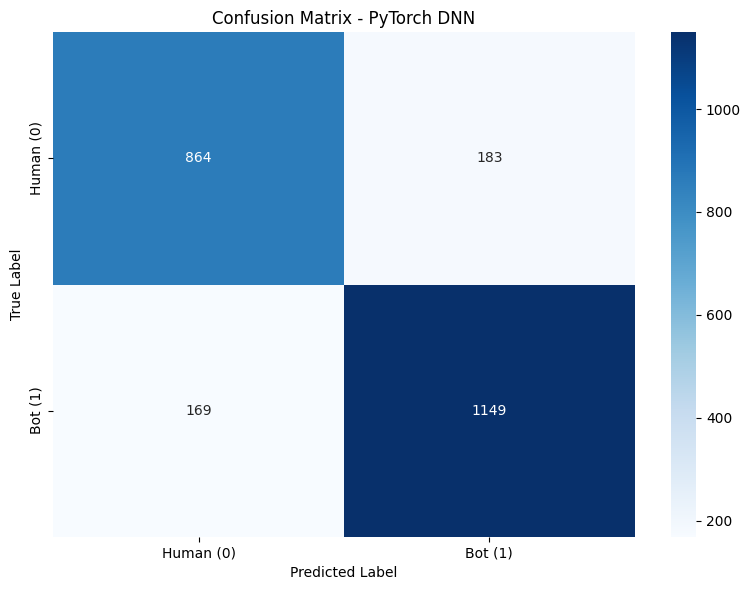

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the DNN Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Human (0)', 'Bot (1)'],
            yticklabels=['Human (0)', 'Bot (1)'])

plt.title('Confusion Matrix - PyTorch DNN')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

**SECTION XAI:** This will display XAI using SHAP:


--- Direct Colab XAI Output ---
Calculating SHAP values for the test set (this may take a moment)...

1. GLOBAL EXPLANATION: Top factors driving model predictions overall


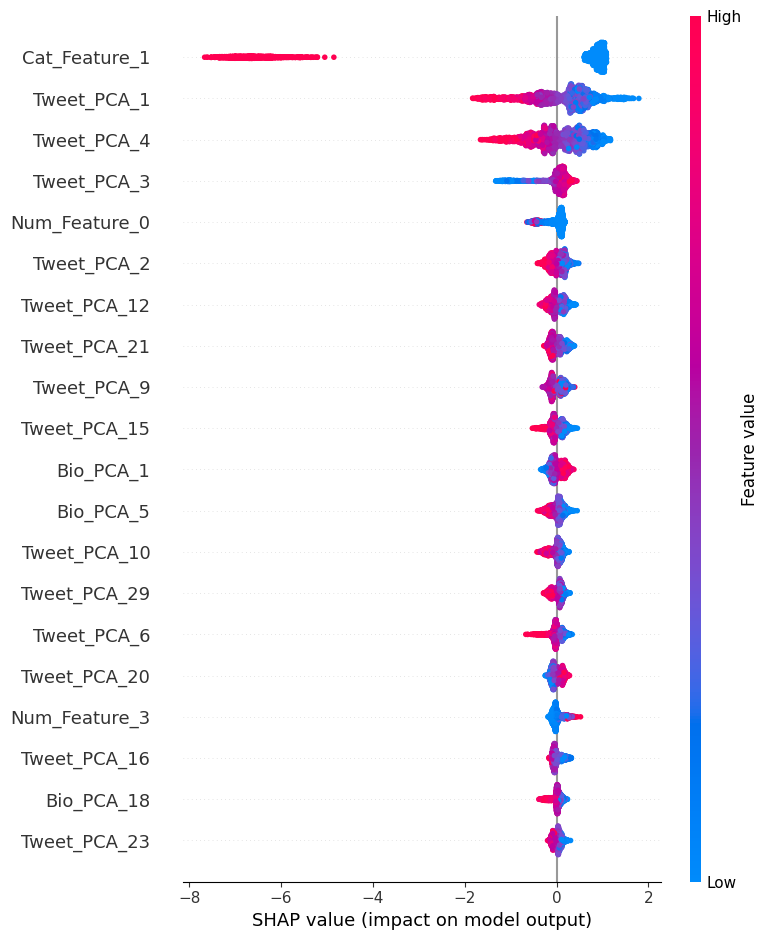


2. LOCAL EXPLANATION: Why was User 1467 flagged as a Bot?


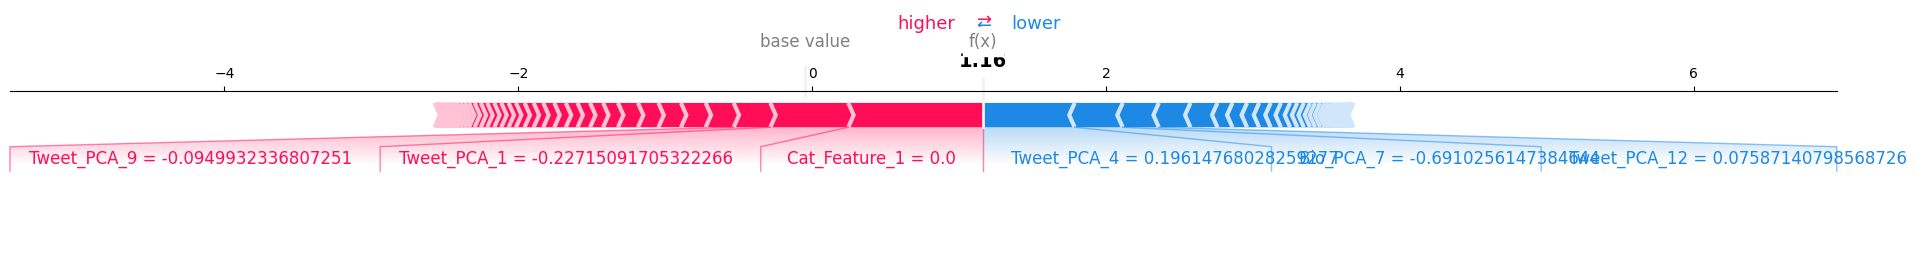

In [ ]:
# ==============================================================================
# Section 14: Direct Colab XAI Visualization (Updated)
# ==============================================================================
import shap
import matplotlib.pyplot as plt

print("--- Direct Colab XAI Output ---")

# 1. Initialize Explainer and Calculate Global SHAP Values
print("Calculating SHAP values for the test set (this may take a moment)...")
# Safely grab the model whether it's currently in memory as xgb_enriched or loaded_xgb
active_xgb = xgb_enriched if 'xgb_enriched' in globals() else loaded_xgb
explainer = shap.TreeExplainer(active_xgb)

# This calculates the marginal contribution of all 76 features for every single user in the test set
shap_values = explainer.shap_values(X_test_enriched)

# 2. Global Explainability (Summary Plot)
print("\n1. GLOBAL EXPLANATION: Top factors driving model predictions overall")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_enriched, feature_names=feature_names, show=False)
plt.tight_layout()
plt.show()

# 3. Local Explainability (Force Plot for a Specific User)
print("\n2. LOCAL EXPLANATION: Why was User 1467 flagged as a Bot?")
# Using matplotlib=True ensures it renders safely in Colab without needing JS
shap.force_plot(
    explainer.expected_value,
    shap_values[1467],
    X_test_enriched[1467],
    feature_names=feature_names,
    matplotlib=True,
    show=False
)
plt.tight_layout()
plt.show()

**Section 14.1: Interpreting the XAI Feature Drivers**

* Num_Feature_0 to Num_Feature_4 (Numerical Metadata): These represent the raw, continuous statistical numbers extracted directly from a user's profile, such as their account age, total follower count, or total following count.
* Cat_Feature_0 to Cat_Feature_2 (Categorical Metadata): These represent binary or categorical profile settings, such as whether the account is officially verified or if it still uses a default, auto-generated profile picture.
* In_Degree, Out_Degree, Total_Degree, Reciprocity_Ratio (Network Topology): These metrics quantify the user's behavioral network graph. They measure how the user interacts with others, capturing suspicious automated behaviors like spam-following thousands of accounts without receiving mutual follow-backs.
* Tweet_PCA_0 through Tweet_PCA_31 (Compressed Tweet Semantics): Because raw text cannot be fed directly into this type of algorithm, feature extraction is a critical step that directly affects the model's performance. Tools like Principal Component Analysis (PCA) are used to compress heavy language model embeddings. A label like
* Tweet_PCA_1 or Tweet_PCA_2 represents a specific, mathematically compressed "summary component" of the user's historical tweets, capturing underlying linguistic patterns, toxicity, or semantic meaning.   
* Bio_PCA_0 to Bio_PCA_31 (Compressed Bio Semantics): Similar to the tweet features, these 32 components represent the mathematical compression of the text found in the user's profile description.

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Set publication style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300)

# --- PANEL A: Modality Ablation (Macro-F1, ROC-AUC, Human Recall) ---
models = ['Tabular XGBoost\n(Profile Only)', 'Pure R-GCN\n(Graph + Content)', 'Calibrated Late Fusion\n(Hybrid System)']
macro_f1 = [0.7588, 0.8349, 0.8395]
roc_auc  = [0.8078, 0.8967, 0.9019]
human_rec = [0.5900, 0.7300, 0.7300]  # Resolving false positives on legitimate accounts

x = np.arange(len(models))
width = 0.25

rects1 = ax1.bar(x - width, macro_f1, width, label='Macro-F1', color='#4A90E2', edgecolor='black', alpha=0.85)
rects2 = ax1.bar(x, roc_auc, width, label='ROC-AUC', color='#50E3C2', edgecolor='black', alpha=0.85)
rects3 = ax1.bar(x + width, human_rec, width, label='Human Recall (Class 0)', color='#F5A623', edgecolor='black', alpha=0.85)

ax1.set_ylabel('Score / Ratio', fontsize=12, fontweight='bold')
ax1.set_title('(A) Modality Ablation & Recall Progression', fontsize=13, fontweight='bold', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10, fontweight='medium')
ax1.set_ylim(0.4, 1.0)
ax1.legend(loc='lower right', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Add exact value labels above bars
def autolabel(rects, ax):
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f'{h:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

autolabel(rects1, ax1)
autolabel(rects2, ax1)
autolabel(rects3, ax1)

# --- PANEL B: ROC Comparison Across Modeling Stages ---
from sklearn.metrics import roc_curve

# Re-compute curves using vectors in memory from your test partition
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, p_xgb_test)
fpr_rgcn, tpr_rgcn, _ = roc_curve(y_test, p_rgcn_test)
fpr_fused, tpr_fused, _ = roc_curve(y_test, fused_test_probs)

ax2.plot(fpr_xgb, tpr_xgb, label=f'Profile XGBoost (AUC = {roc_auc[0]:.4f})', color='#4A90E2', lw=2, linestyle='--')
ax2.plot(fpr_rgcn, tpr_rgcn, label=f'Pure R-GCN (AUC = {roc_auc[1]:.4f})', color='#50E3C2', lw=2)
ax2.plot(fpr_fused, tpr_fused, label=f'Calibrated Late Fusion (AUC = {roc_auc[2]:.4f})', color='#D0021B', lw=2.5)
ax2.plot([0, 1], [0, 1], color='gray', linestyle=':', lw=1.5, label='Random Classifier')

ax2.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
ax2.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12, fontweight='bold')
ax2.set_title('(B) Test Partition ROC Curves', fontsize=13, fontweight='bold', pad=12)
ax2.legend(loc='lower right', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('report_figure_1_ablation_and_roc.png', dpi=300)
plt.show()

NameError: name 'p_xgb_test' is not defined